## Package installation

In [28]:
%pip install numpy pandas matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Setup and imports

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')

DATA_DIR = Path('data')
FIG_DIR = Path('figures')
OUT_DIR = Path('outputs')

FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)


## Data ingestion

In [30]:
# Load raw datasets
davis_raw = pd.read_csv(DATA_DIR / 'davis_all.csv')
kiba_raw = pd.read_csv(DATA_DIR / 'kiba_all.csv')

print('Raw shapes:')
print(f'DAVIS: {davis_raw.shape}')
print(f'KIBA:  {kiba_raw.shape}')
print('\nColumns:')
print('DAVIS:', davis_raw.columns.tolist())
print('KIBA: ', kiba_raw.columns.tolist())
display(davis_raw.head())
display(kiba_raw.head())


Raw shapes:
DAVIS: (30056, 3)
KIBA:  (118254, 3)

Columns:
DAVIS: ['compound_iso_smiles', 'target_sequence', 'affinity']
KIBA:  ['compound_iso_smiles', 'target_sequence', 'affinity']


,compound_iso_smiles,target_sequence,affinity
0,O=C(NC1CCNCC1)c1[nH]ncc1NC(=O)c1c(Cl)cccc1Cl,MVSYWDTGVLLCALLSCLLLTGSSSGSKLKDPELSLKGTQHIMQAG...,5.0
1,CSc1cccc(Nc2ncc3cc(-c4c(Cl)cccc4Cl)c(=O)n(C)c3...,MLRGGRRGQLGWHSWAAGPGSLLAWLILASAGAAPCPDACCPHGSS...,5.0
2,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,MGPAPLPLLLGLFLPALWRRAITEAREEAKPYPLFPGPFPGSLQTD...,5.0
3,COC1C(N(C)C(=O)c2ccccc2)CC2OC1(C)n1c3ccccc3c3c...,MFRKKKKKRPEISAPQNFQHRVHTSFDPKEGKFVGLPPQWQNILDT...,5.0
4,CN(C)CC=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc...,TMPPRPSSGELWGIHLMPPRILVECLLPNGMIVTLECLREATLITI...,5.0


,compound_iso_smiles,target_sequence,affinity
0,O=C1c2c(c3c4ccc(O)cc4n(C4OC(CO)C(O)C(O)C4O)c3c...,MSANNSPPSAQKSVLPTAIPAVLPAASPCSSPKTGLSARLSNGSFS...,9.798970
1,N#Cc1ccc(NC(=O)Nc2ccnc3cc(C(F)(F)F)ccc23)nc1,MLGAVEGPRWKQAEDIRDIYDFRDVLGTGAFSEVILAEDKRTQKLV...,11.400000
2,CCNc1nc2cc(Cl)c(OC)cc2nc1NCC,MEPAAGFLSPRPFQRAAAAPAPPAGPGPPPSALRGPELEMLAGLPT...,11.200000
3,CNc1ncnc2c1N=C(c1ccc(NC(=O)Nc3cccc(C(F)(F)F)c3...,MELRVGNRYRLGRKIGSGSFGDIYLGTDIAAGEEVAIKLECVKTKH...,11.200000
4,C#Cc1cc2c(cc1OC)-c1[nH]nc(-c3ccc(C#N)nc3)c1C2,MRGARGAWDFLCVLLLLLRVQTGSSQPSVSPGEPSPPSIHPGKSDL...,11.999998


## Cleaning pipeline
Transforms DAVIS from nM Kd to pKd, removes missing/blank IDs and non-finite values and averages any duplicate (ligand, target) pairs

In [31]:

KEYS = ['compound_iso_smiles', 'target_sequence']
REQUIRED = KEYS + ['affinity']

def clean_dataset(raw, name):
    df = raw[REQUIRED].copy()

    # Convert affinity to numeric; invalid strings become NaN.
    df['affinity'] = pd.to_numeric(
        df['affinity'], errors='coerce'
    )

    # Dataset-specific affinity conversion.
    if name.upper() == 'DAVIS':
        # Raw Kd is in nM. Only positive, finite values are valid.
        valid_affinity = (
            np.isfinite(df['affinity'].to_numpy(dtype=float)) &
            (df['affinity'].to_numpy(dtype=float) > 0)
        )

        df.loc[~valid_affinity, 'affinity'] = np.nan

        # Convert Kd (nM) to pKd.
        df.loc[valid_affinity, 'affinity'] = (
            9 - np.log10(df.loc[valid_affinity, 'affinity'])
        )

    elif name.upper() == 'KIBA':
        # KIBA scores are already in the supplied transformed scale.
        df.loc[
            ~np.isfinite(df['affinity'].to_numpy(dtype=float)),
            'affinity'
        ] = np.nan

    else:
        raise ValueError(f"Unknown dataset: {name}")

    # Remove invalid affinity values and missing/blank IDs.
    finite_mask = np.isfinite(
        df['affinity'].to_numpy(dtype=float)
    )

    valid_ids = (
        df[KEYS].notna().all(axis=1) &
        df[KEYS].astype(str)
          .apply(lambda c: c.str.strip().ne(''))
          .all(axis=1)
    )

    df_cleaned = df.loc[valid_ids & finite_mask].copy()

    # Audit duplicate ligand-target pairs.
    before_dedup = len(df_cleaned)
    dup_mask = df_cleaned.duplicated(KEYS, keep=False)
    dup_groups = (
        df_cleaned.loc[dup_mask, KEYS]
        .drop_duplicates()
        .shape[0]
    )
    dup_rows = int(dup_mask.sum())

    # Average duplicate observations after conversion.
    clean = (
        df_cleaned.groupby(KEYS, as_index=False, sort=False)
        .agg(affinity=('affinity', 'mean'))
    )

    audit = {
        'Dataset': name,
        'Affinity scale': (
            'pKd (converted from nM)'
            if name.upper() == 'DAVIS'
            else 'Original KIBA score'
        ),
        'Input rows': len(raw),
        'Invalid/non-finite/nonpositive scores': int(
            (~finite_mask).sum()
        ),
        'Missing/blank IDs': int((~valid_ids).sum()),
        'Rows before dedup': before_dedup,
        'Total rows in duplicate groups': dup_rows,
        'Unique duplicated pair groups': int(dup_groups),
        'Excess rows removed by aggregation': int(dup_rows) - int(dup_groups),
        'Rows after dedup (observed pairs)': len(clean),
        'Unique ligands': clean[KEYS[0]].nunique(),
        'Unique targets': clean[KEYS[1]].nunique(),
    }

    return clean, audit


# Clean datasets
davis, davis_audit = clean_dataset(davis_raw, 'DAVIS')
kiba, kiba_audit = clean_dataset(kiba_raw, 'KIBA')

# Review the cleaning audit
audit_df = pd.DataFrame([davis_audit, kiba_audit])
display(audit_df)
display(davis.head())
display(kiba.head())

# Save audit and cleaned datasets
audit_df.to_csv(OUT_DIR / 'cleaning_audit.csv', index=False)
davis.to_csv(DATA_DIR / 'davis_clean.csv', index=False)
kiba.to_csv(DATA_DIR / 'kiba_clean.csv', index=False)


,Dataset,Affinity scale,Input rows,Invalid/non-finite/nonpositive scores,Missing/blank IDs,Rows before dedup,Total rows in duplicate groups,Unique duplicated pair groups,Excess rows removed by aggregation,Rows after dedup (observed pairs),Unique ligands,Unique targets
0,DAVIS,pKd (converted from nM),30056,0,0,30056,5508,1224,4284,25772,68,379
1,KIBA,Original KIBA score,118254,0,0,118254,1070,473,597,117657,2068,229


,compound_iso_smiles,target_sequence,affinity
0,O=C(NC1CCNCC1)c1[nH]ncc1NC(=O)c1c(Cl)cccc1Cl,MVSYWDTGVLLCALLSCLLLTGSSSGSKLKDPELSLKGTQHIMQAG...,8.30103
1,CSc1cccc(Nc2ncc3cc(-c4c(Cl)cccc4Cl)c(=O)n(C)c3...,MLRGGRRGQLGWHSWAAGPGSLLAWLILASAGAAPCPDACCPHGSS...,8.30103
2,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,MGPAPLPLLLGLFLPALWRRAITEAREEAKPYPLFPGPFPGSLQTD...,8.30103
3,COC1C(N(C)C(=O)c2ccccc2)CC2OC1(C)n1c3ccccc3c3c...,MFRKKKKKRPEISAPQNFQHRVHTSFDPKEGKFVGLPPQWQNILDT...,8.30103
4,CN(C)CC=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc...,TMPPRPSSGELWGIHLMPPRILVECLLPNGMIVTLECLREATLITI...,8.30103


,compound_iso_smiles,target_sequence,affinity
0,O=C1c2c(c3c4ccc(O)cc4n(C4OC(CO)C(O)C(O)C4O)c3c...,MSANNSPPSAQKSVLPTAIPAVLPAASPCSSPKTGLSARLSNGSFS...,10.343554
1,N#Cc1ccc(NC(=O)Nc2ccnc3cc(C(F)(F)F)ccc23)nc1,MLGAVEGPRWKQAEDIRDIYDFRDVLGTGAFSEVILAEDKRTQKLV...,11.400000
2,CCNc1nc2cc(Cl)c(OC)cc2nc1NCC,MEPAAGFLSPRPFQRAAAAPAPPAGPGPPPSALRGPELEMLAGLPT...,11.200000
3,CNc1ncnc2c1N=C(c1ccc(NC(=O)Nc3cccc(C(F)(F)F)c3...,MELRVGNRYRLGRKIGSGSFGDIYLGTDIAAGEEVAIKLECVKTKH...,11.200000
4,C#Cc1cc2c(cc1OC)-c1[nH]nc(-c3ccc(C#N)nc3)c1C2,MRGARGAWDFLCVLLLLLRVQTGSSQPSVSPGEPSPPSIHPGKSDL...,11.999998


## Summary table of each dataset after cleaning

In [32]:

def dataset_summary(clean, name):
    n_lig = clean['compound_iso_smiles'].nunique()
    n_tgt = clean['target_sequence'].nunique()
    n_pairs = len(clean)

    possible = n_lig * n_tgt
    s = clean['affinity']

    return {
        'Dataset': name,
        'Unique ligands': n_lig,
        'Unique targets': n_tgt,
        'Observed pairs': n_pairs,
        'Possible pairs (ligands * targets)': possible,
        'Coverage (%)': (
            100 * n_pairs / possible if possible else 0
        ),
        'Sparsity (%)': (
            100 * (1 - n_pairs / possible) if possible else 0
        ),
        'Mean': s.mean(),
        'Median': s.median(),
        'Std': s.std(),
        'Min': s.min(),
        'Q1': s.quantile(0.25),
        'Q3': s.quantile(0.75),
        'Max': s.max(),
        'Zero scores': int((s == 0).sum()),
    }


summary = pd.DataFrame([
    dataset_summary(davis, 'DAVIS (pKd)'),
    dataset_summary(kiba, 'KIBA'),
])

display(summary.round(3))
summary.to_csv(OUT_DIR / 'dataset_summary.csv', index=False)


,Dataset,Unique ligands,Unique targets,Observed pairs,Possible pairs (ligands * targets),Coverage (%),Sparsity (%),Mean,Median,Std,Min,Q1,Q3,Max,Zero scores
0,DAVIS (pKd),68,379,25772,25772,100.000,0.000,8.272,8.301,0.057,7.974,8.268,8.301,8.301,0
1,KIBA,2068,229,117657,473572,24.845,75.155,11.721,11.527,0.834,0.000,11.200,11.924,17.200,1


## Distribution plots
Showing where the values cluster for DAVIS and KIBA

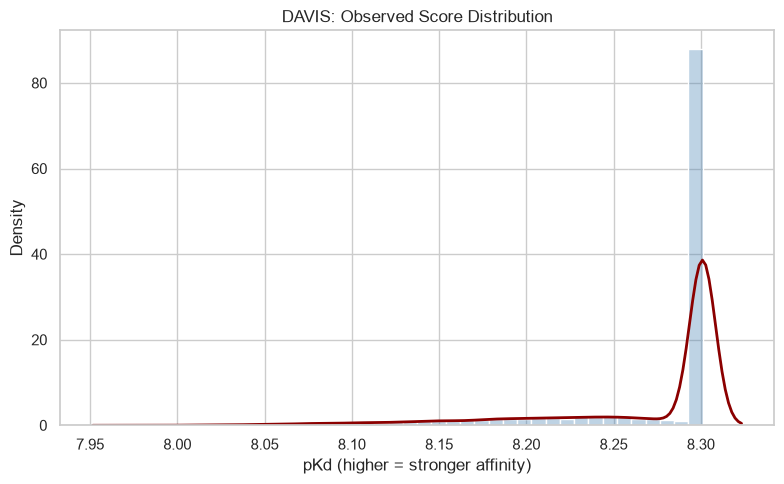

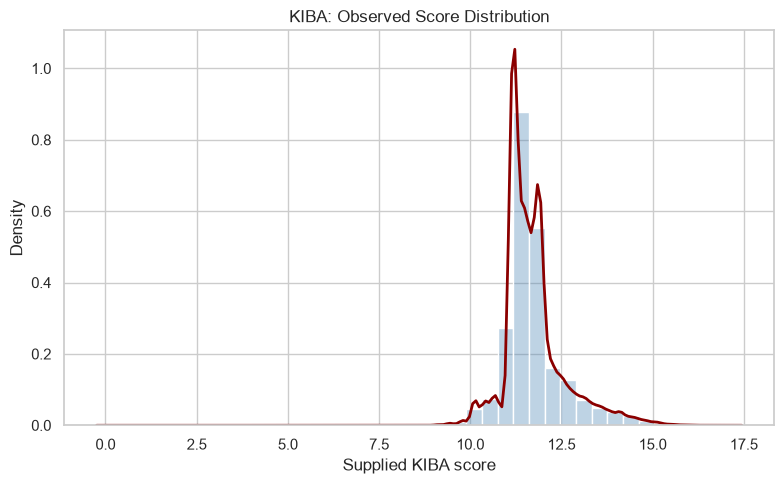

In [33]:
def plot_distribution(df, name, xlabel, filename):
    scores = df['affinity'].dropna()

    fig, ax = plt.subplots(figsize=(8, 5))
    
    sns.histplot(
        scores, 
        bins=40, 
        stat='density', 
        color='steelblue', 
        alpha=0.35, 
        ax=ax
        )
    
    if scores.nunique() > 1:
        sns.kdeplot(
            x=scores, 
            color='darkred', 
            linewidth=2, 
            ax=ax
            )
    
    ax.set_title(f'{name}: Observed Score Distribution')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Density')
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=300, bbox_inches='tight')
    plt.show()

plot_distribution(davis, 'DAVIS', 'pKd (higher = stronger affinity)', 'davis_distribution.png')
plot_distribution(kiba, 'KIBA', 'Supplied KIBA score', 'kiba_distribution.png')


## Heatmaps
Visual comparison of measured vs missing interactions

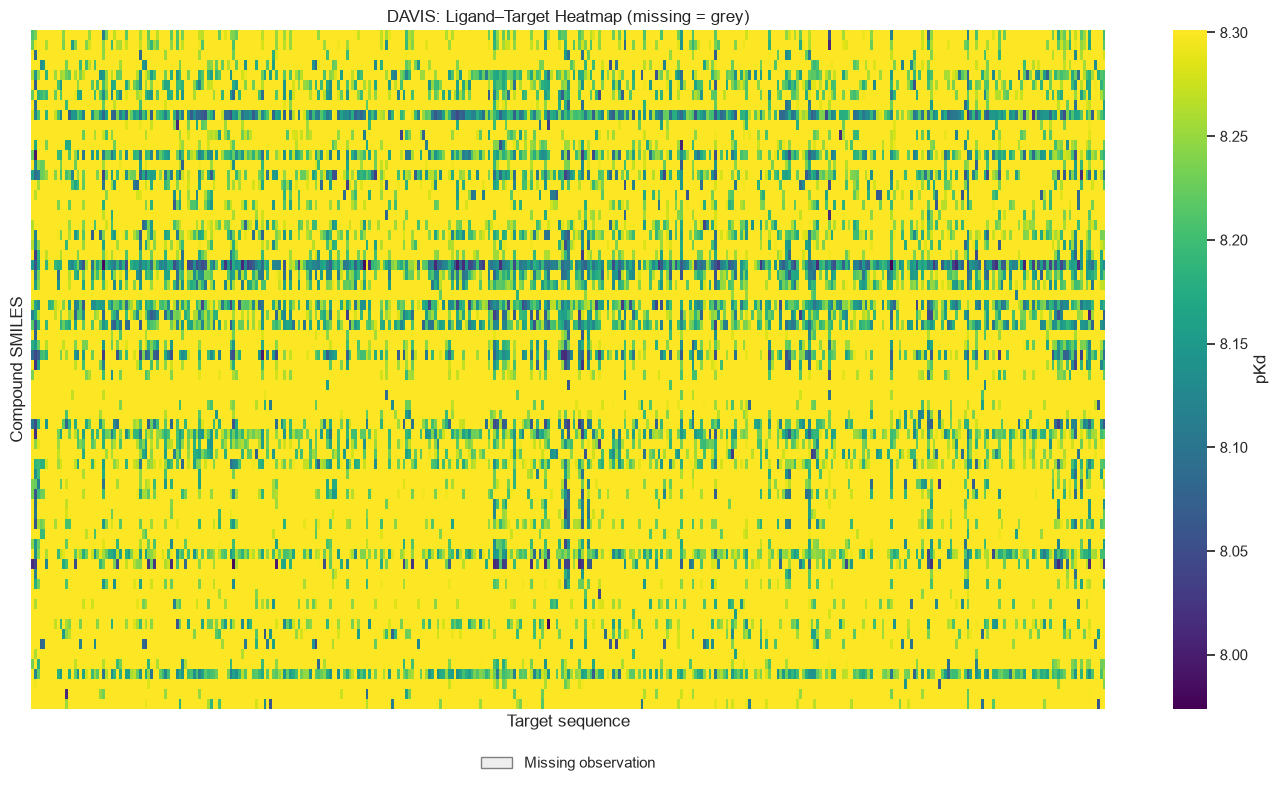

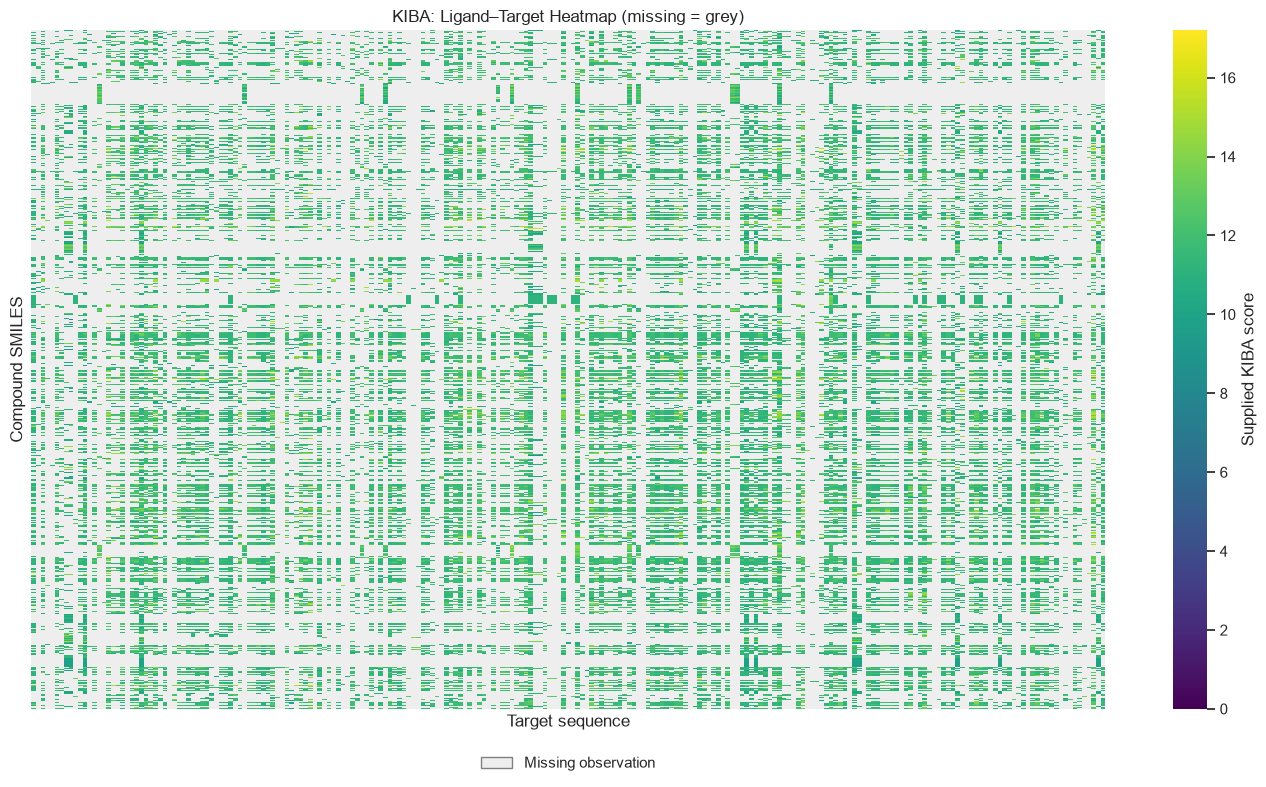

In [34]:
from matplotlib.patches import Patch

def plot_heatmap(df, name, filename):
    matrix = df.pivot(
        index='compound_iso_smiles', 
        columns='target_sequence', 
        values='affinity'
        )
    
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.set_facecolor("#EEEEEE")
    
    sns.heatmap(
        matrix,
        cmap='viridis',
        mask=matrix.isna(),
        xticklabels=False,
        yticklabels=False,
        cbar_kws={'label': 'pKd' if name == 'DAVIS' else 'Supplied KIBA score'},
        ax=ax,
    )
    
    ax.set_title(f'{name}: Ligand–Target Heatmap (missing = grey)')
    ax.set_xlabel('Target sequence')
    ax.set_ylabel('Compound SMILES')
    ax.legend(
        handles=[Patch(facecolor="#EEEEEE", edgecolor="gray", label='Missing observation')], 
        loc='upper center', 
        bbox_to_anchor=(0.5, -0.05),
        frameon=False
        )
    
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=300, bbox_inches='tight')
    plt.show()

plot_heatmap(davis, 'DAVIS', 'davis_heatmap.png')
plot_heatmap(kiba, 'KIBA', 'kiba_heatmap.png')


## Coverage/degree plots
Groups by ligand to count how many targets it was tested against, and by target to count how many ligands it was tested against.

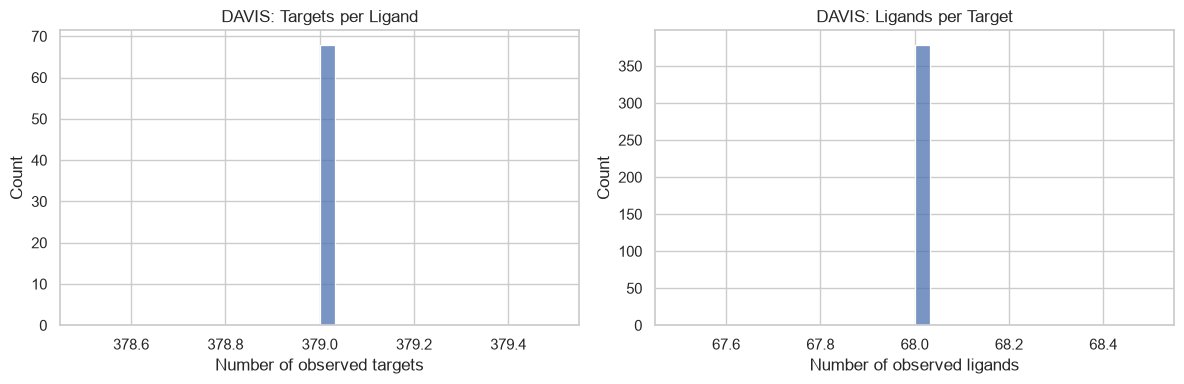

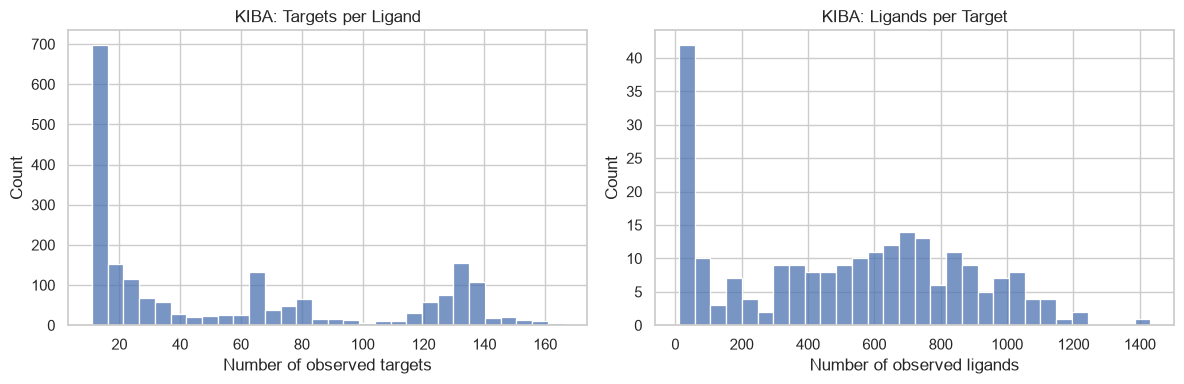

In [35]:
def plot_coverage(df, name):
    lig_cov = df.groupby('compound_iso_smiles')['target_sequence'].nunique()
    tgt_cov = df.groupby('target_sequence')['compound_iso_smiles'].nunique()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    sns.histplot(lig_cov, bins=30, ax=axes[0])
    axes[0].set_title(f'{name}: Targets per Ligand')
    axes[0].set_xlabel('Number of observed targets')
    
    sns.histplot(tgt_cov, bins=30, ax=axes[1])
    axes[1].set_title(f'{name}: Ligands per Target')
    axes[1].set_xlabel('Number of observed ligands')
    
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name.lower()}_coverage.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_coverage(davis, 'DAVIS')
plot_coverage(kiba, 'KIBA')


KIBA 
<br> Targets per ligand: Most ligands have relatively limited target coverage, while a smaller group of ligands interacts with many targets. This suggests an uneven distribution of ligand–target interactions
<br> Ligands per target: Some targets have very few associated ligands, while others have extensive ligand coverage. This indicates an imbalance in the number of observations available for different targets
<br>
<br> DAVIS
<br> Targets per ligand: Every ligand is associated with the same number of targets 
<br> Ligands per target: Every target is associated with the same number of ligands

## Property summary table
Comparing the chemical diversity (SMILES lengths) and protein sequence diversity (protein lengths).

In [36]:

def seq_props(df, name):
    lig = df['compound_iso_smiles'].drop_duplicates().dropna()
    tgt = df['target_sequence'].drop_duplicates().dropna()

    return {
        'Dataset': name,
        'Unique ligands': len(lig),
        'Unique targets': len(tgt),
        'Mean SMILES length': lig.str.len().mean(),
        'Median SMILES length': lig.str.len().median(),
        'Mean protein length': tgt.str.len().mean(),
        'Median protein length': tgt.str.len().median(),
    }


seq_df = pd.DataFrame([
    seq_props(davis, 'DAVIS'),
    seq_props(kiba, 'KIBA')
])

display(seq_df.round(2))

seq_df.to_csv(
    OUT_DIR / 'sequence_properties.csv',
    index=False
)


,Dataset,Unique ligands,Unique targets,Mean SMILES length,Median SMILES length,Mean protein length,Median protein length
0,DAVIS,68,379,54.18,53.0,744.85,632.0
1,KIBA,2068,229,49.64,46.0,728.96,620.0


# Length distribution plots
Shows the spread and diversity of the inputs

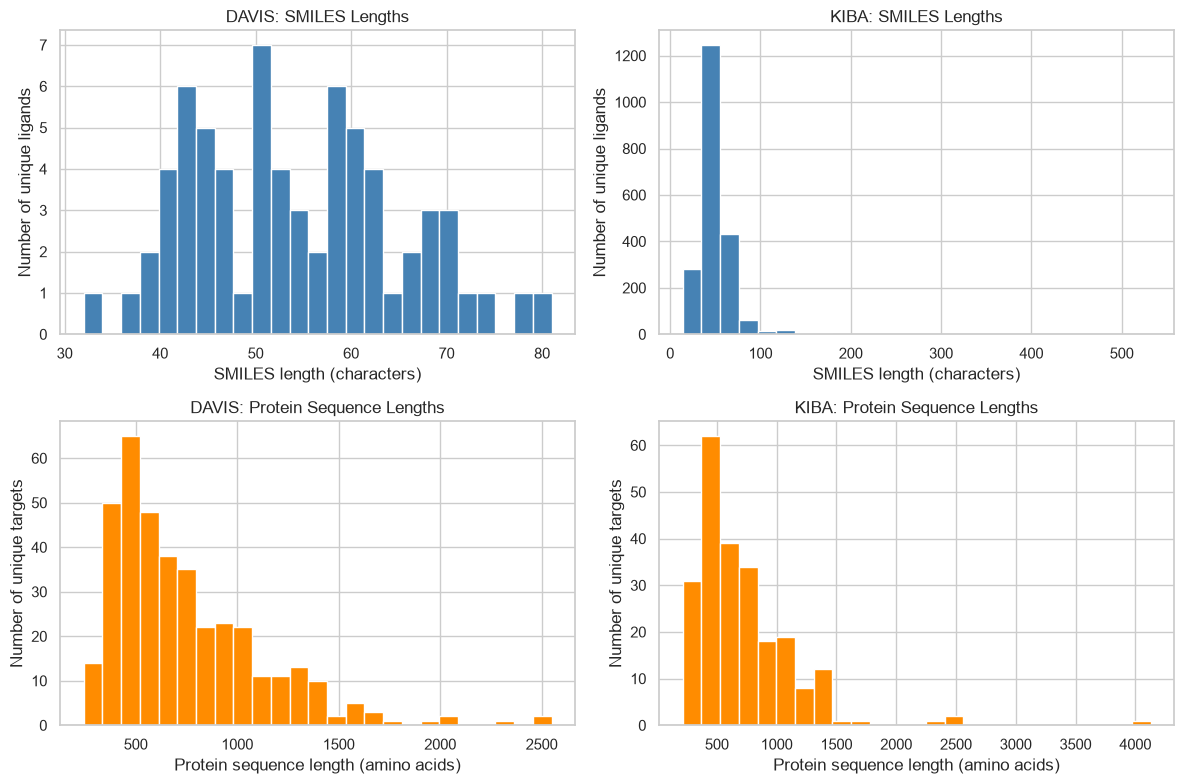

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, df, name in [
    (0, davis, "DAVIS"),
    (1, kiba, "KIBA"),
]:
    # Count each unique ligand and target once
    ligands = df['compound_iso_smiles'].drop_duplicates()
    targets = df['target_sequence'].drop_duplicates()

    ligand_lengths = ligands.str.len()
    target_lengths = targets.str.len()

    # SMILES lengths
    axes[0, col].hist(
        ligand_lengths.dropna(),
        bins=25,
        color='steelblue',
        edgecolor='white'
    )
    axes[0, col].set_title(f'{name}: SMILES Lengths')
    axes[0, col].set_xlabel('SMILES length (characters)')
    axes[0, col].set_ylabel('Number of unique ligands')

    # Protein sequence lengths
    axes[1, col].hist(
        target_lengths.dropna(),
        bins=25,
        color='darkorange',
        edgecolor='white'
    )
    axes[1, col].set_title(f'{name}: Protein Sequence Lengths')
    axes[1, col].set_xlabel('Protein sequence length (amino acids)')
    axes[1, col].set_ylabel('Number of unique targets')

fig.tight_layout()
fig.savefig(
    FIG_DIR / 'input_length_distributions.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


DAVIS:
<br> Most protein sequences are concentrated between approximately 350 and 1,000 amino acids.
<br> The mean (744.85) is higher than the median (632).
<br> A small number of proteins have considerably longer sequences.
<br>
<br> KIBA:
<br> Most protein sequences are also concentrated between approximately 350 and 1,000 amino acids.
<br> The mean (728.96) is slightly higher than the median (620).
<br> There are a few exceptionally long protein sequences.